# Corpus — Préparer les témoignages

Ce notebook extrait les témoignages textuels du corpus brut et les prépare pour le pipeline `MESSAGE → ÉMOTION → VOIX → AVATAR`.

**Ce qui compte** : le texte que l'avatar va prononcer et les indices de personnalité pour incarner le message.

**Output** : `data/processed/corpus.parquet` — messages propres, prêts pour l'analyse émotionnelle.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display, HTML
import re
import json
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'font.size': 12, 'figure.facecolor': 'white'})
sns.set_palette('Set2')

---
## 1. Charger les données brutes

In [2]:
data_path = list(Path('../data/raw').glob('*.xlsx'))[0]

sheets = {
    'F1': pd.read_excel(data_path, sheet_name='Familles 1'),
    'F2': pd.read_excel(data_path, sheet_name='Familles 2'),
    'NP': pd.read_excel(data_path, sheet_name='Nouvelle Plateforme'),
}

for k, v in sheets.items():
    print(f'{k}: {len(v):,} messages')
print(f'\nTotal brut: {sum(len(v) for v in sheets.values()):,}')

F1: 1,782 messages
F2: 6,810 messages
NP: 477 messages

Total brut: 9,069


---
## 2. Extraire les champs utiles

Pour l'avatar, on a besoin de :
- **Le témoignage** (motivation) — ce que l'avatar va *dire*
- **La description personnelle** — qui donne le *ton*, la *personnalité*
- **Les infos complémentaires** — contexte supplémentaire

Les métadonnées (durée d'accueil, taille de la chambre, enfants…) ne servent pas directement l'avatar mais peuvent enrichir le contexte émotionnel.

In [3]:
def extract_messages(df, source, col_map):
    """Extrait et renomme les colonnes utiles d'une feuille."""
    out = {}
    for target, origin in col_map.items():
        if origin in df.columns:
            out[target] = df[origin].values
        else:
            out[target] = [None] * len(df)
    
    result = pd.DataFrame(out)
    result['source'] = source
    return result

# Mapping commun : nom cible -> nom d'origine dans l'Excel
base_map = {
    'testimony': 'Motivations / Pourquoi CALM',
    'self_description': 'Parlez nous de vous',
    'space_description': "Type d'espace mis à disposition ",
    'extra_info': 'Autres infos',
    'postal_code': 'CP',
    'hosting_duration': "Temps d'accueil",
    'accepts_children': 'avec enfants ? ',
}

dfs = [
    extract_messages(sheets['F1'], 'F1', base_map),
    extract_messages(sheets['F2'], 'F2', {**base_map, 'age': 'Age', 'capacity': "Capacité d'accueil"}),
    extract_messages(sheets['NP'], 'NP', {**base_map, 'birth_date': 'Date de naissance', 'capacity': "Capacité d'accueil"}),
]

corpus = pd.concat(dfs, ignore_index=True)
corpus.insert(0, 'id', [f'{row.source}_{i:04d}' for i, row in corpus.iterrows()])

print(f'Corpus assemblé : {len(corpus):,} messages')
print(f'Sources : {corpus["source"].value_counts().to_dict()}')

Corpus assemblé : 9,069 messages
Sources : {'F2': 6810, 'F1': 1782, 'NP': 477}


---
## 3. Nettoyer le texte

In [4]:
def clean(text):
    """Nettoie un texte en préservant l'authenticité."""
    if pd.isna(text) or not isinstance(text, str):
        return None
    text = text.replace('\r\n', '\n').replace('\r', '\n')
    text = re.sub(r'[ \t]+', ' ', text)  # espaces multiples
    text = re.sub(r'\n{3,}', '\n\n', text)  # sauts de ligne excessifs
    text = text.strip()
    return text if len(text) > 0 else None

text_cols = ['testimony', 'self_description', 'space_description', 'extra_info']
for col in text_cols:
    corpus[col] = corpus[col].apply(clean)

# Code postal propre
def clean_cp(cp):
    if pd.isna(cp): return None
    s = str(cp).strip()
    if any(c.isalpha() for c in s): return s
    try: return str(int(float(s))).zfill(5)
    except: return s

corpus['postal_code'] = corpus['postal_code'].apply(clean_cp)

# Filtrer : on ne garde QUE les lignes sans valeurs nulles dans les champs texte essentiels
before = len(corpus)
corpus = corpus[corpus['testimony'].notna() & corpus['self_description'].notna()].copy()
corpus = corpus.reset_index(drop=True)
corpus['id'] = [f'{row.source}_{i:04d}' for i, row in corpus.iterrows()]

print(f'Avant filtrage : {before:,} messages')
print(f'Après filtrage (testimony + description non-null) : {len(corpus):,} messages')
print(f'Supprimés : {before - len(corpus):,}')
print()
for col in text_cols:
    n = corpus[col].notna().sum()
    print(f'{col:20s}: {n:,}/{len(corpus):,} ({n/len(corpus)*100:.0f}%)')

Avant filtrage : 9,069 messages
Après filtrage (testimony + description non-null) : 8,707 messages
Supprimés : 362

testimony           : 8,707/8,707 (100%)
self_description    : 8,707/8,707 (100%)
space_description   : 8,702/8,707 (100%)
extra_info          : 3,351/8,707 (38%)


---
## 4. Construire le texte complet pour l'avatar

L'avatar va incarner un message. Il a besoin d'un **texte principal** à prononcer et d'un **contexte de personnalité** qui influence son ton.

On fusionne intelligemment les champs texte :
- `testimony` → le contenu principal (motivation, histoire, émotion)
- `self_description` → éléments de personnalité
- `extra_info` → complément contextuel

In [5]:
def build_speakable_text(row):
    """Construit le texte que l'avatar pourrait prononcer.
    
    Priorité: testimony > self_description > extra_info
    On prend le champ le plus riche émotionnellement.
    """
    parts = []
    if pd.notna(row['testimony']):
        parts.append(row['testimony'])
    if pd.notna(row['self_description']):
        parts.append(row['self_description'])
    if pd.notna(row['extra_info']):
        parts.append(row['extra_info'])
    return '\n\n'.join(parts) if parts else None

corpus['full_text'] = corpus.apply(build_speakable_text, axis=1)
corpus['full_text_length'] = corpus['full_text'].apply(lambda x: len(x) if pd.notna(x) else 0)
corpus['testimony_length'] = corpus['testimony'].apply(lambda x: len(x) if pd.notna(x) else 0)

# Filtrer : on garde les messages qui ont au moins un contenu textuel exploitable
usable = corpus[corpus['full_text'].notna()].copy()
print(f'Messages exploitables : {len(usable):,} / {len(corpus):,}')
print(f'Messages avec témoignage : {usable["testimony"].notna().sum():,}')
print(f'\nLongueur du texte complet :')
print(usable['full_text_length'].describe()[['mean', '50%', 'min', 'max']].to_string())

Messages exploitables : 8,707 / 8,707
Messages avec témoignage : 8,707

Longueur du texte complet :
mean     579.309062
50%      474.000000
min        4.000000
max     5418.000000


---
## 5. Visualiser le corpus

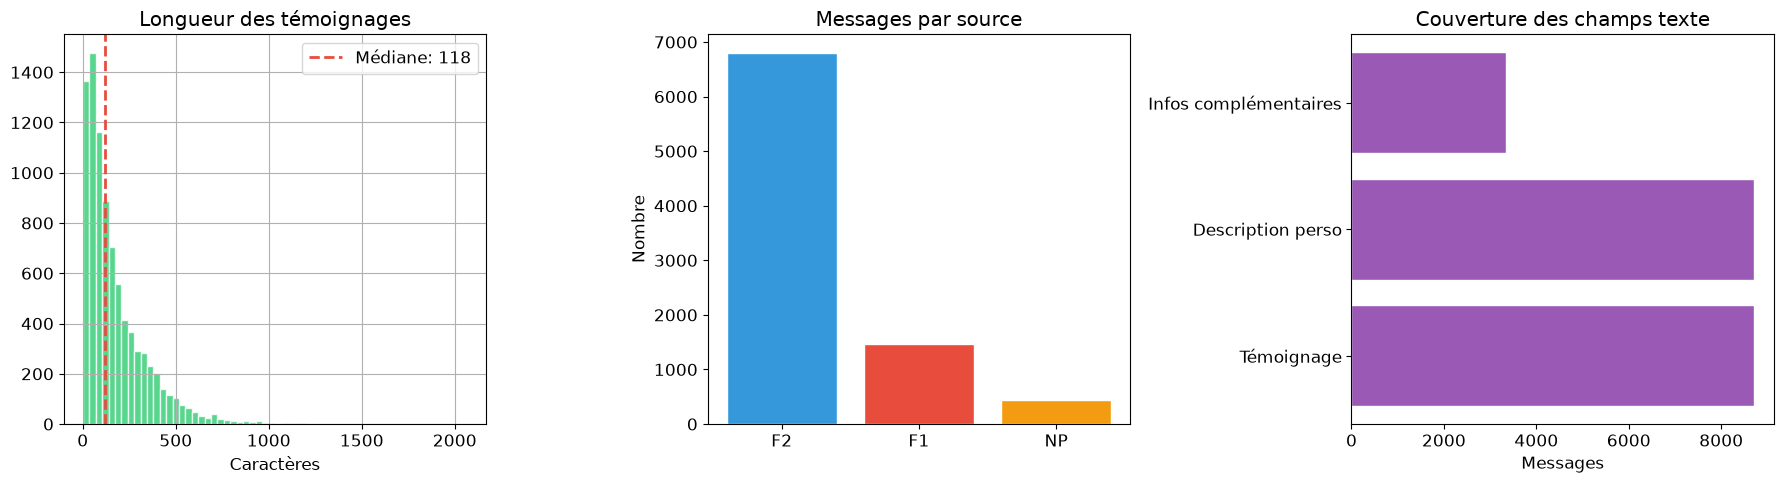

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribution des longueurs
usable['testimony_length'].hist(bins=60, ax=axes[0], color='#2ecc71', edgecolor='white', alpha=0.8)
axes[0].axvline(usable['testimony_length'].median(), color='#e74c3c', linestyle='--', linewidth=2, label=f'Médiane: {usable["testimony_length"].median():.0f}')
axes[0].set_xlabel('Caractères')
axes[0].set_title('Longueur des témoignages')
axes[0].legend()

# Source
src_counts = usable['source'].value_counts()
colors_src = ['#3498db', '#e74c3c', '#f39c12'][:len(src_counts)]
axes[1].bar(src_counts.index, src_counts.values, color=colors_src, edgecolor='white')
axes[1].set_title('Messages par source')
axes[1].set_ylabel('Nombre')

# Disponibilité des champs texte
coverage = pd.DataFrame({
    'Champ': ['Témoignage', 'Description perso', 'Infos complémentaires'],
    'Disponible': [
        usable['testimony'].notna().sum(),
        usable['self_description'].notna().sum(),
        usable['extra_info'].notna().sum(),
    ]
})
axes[2].barh(coverage['Champ'], coverage['Disponible'], color='#9b59b6', edgecolor='white')
axes[2].set_title('Couverture des champs texte')
axes[2].set_xlabel('Messages')

plt.tight_layout()
plt.show()

---
## 6. Échantillons

Quelques messages du corpus pour voir ce qu'on a entre les mains.

In [7]:
def show_message(row):
    """Affiche un message du corpus de façon lisible."""
    html = f"""
    <div style='border-left:4px solid #3498db; padding:12px 16px; margin:12px 0; background:#f8f9fa; border-radius:4px;'>
        <div style='color:#7f8c8d; font-size:12px; margin-bottom:8px;'>
            <b>{row['id']}</b> · Source: {row['source']}
            {f" · CP: {row['postal_code']}" if pd.notna(row['postal_code']) else ''}
            {f" · Durée: {row['hosting_duration']}" if pd.notna(row['hosting_duration']) else ''}
        </div>
    """
    
    if pd.notna(row['testimony']):
        text = row['testimony'].replace('\n', '<br>')
        html += f"<div style='font-style:italic; color:#2c3e50; margin-bottom:10px;'>❝ {text} ❞</div>"
    
    if pd.notna(row['self_description']):
        desc = row['self_description'].replace('\n', '<br>')
        html += f"<div style='color:#555; font-size:13px;'><b>Qui suis-je :</b> {desc}</div>"
    
    html += f"<div style='color:#95a5a6; font-size:11px; margin-top:6px;'>{row['full_text_length']} caractères</div>"
    html += "</div>"
    display(HTML(html))


# 5 messages aléatoires de bonne longueur
samples = usable[usable['testimony_length'] > 100].sample(5, random_state=42)
for _, row in samples.iterrows():
    show_message(row)

---
## 7. Sauvegarder le corpus propre

In [8]:
out_dir = Path('../data/processed')
out_dir.mkdir(exist_ok=True)

# Convertir les colonnes mixtes (int+str) en string pour Parquet
for col in usable.columns:
    if usable[col].dtype == 'object':
        usable[col] = usable[col].astype(str).replace('None', None).replace('nan', None)

# Sauvegarder le corpus complet
usable.to_parquet(out_dir / 'corpus.parquet', index=False)
usable.to_csv(out_dir / 'corpus.csv', index=False)

# Stats rapides
stats = {
    'total_messages': len(usable),
    'with_testimony': int(usable['testimony'].notna().sum()),
    'with_description': int(usable['self_description'].notna().sum()),
    'avg_testimony_length': float(usable['testimony_length'].mean()),
    'sources': usable['source'].value_counts().to_dict(),
}
with open(out_dir / 'corpus_stats.json', 'w') as f:
    json.dump(stats, f, indent=2)

print(f'\u2713 Corpus sauvegardé : {len(usable):,} messages')
print(f'  \u2192 {out_dir / "corpus.parquet"}')
print(f'  \u2192 {out_dir / "corpus.csv"}')
print(f'  \u2192 {out_dir / "corpus_stats.json"}')
print(f'\nProchaine étape : 02_emotion.ipynb')

✓ Corpus sauvegardé : 8,707 messages
  → ../data/processed/corpus.parquet
  → ../data/processed/corpus.csv
  → ../data/processed/corpus_stats.json

Prochaine étape : 02_emotion.ipynb
